# Cantilever cylinder under a follower pressure

Schweizerhof and Ramm [1], Section 6.4 (Fig. 12 on p. 1110, Table 4 on
p. 1111, Fig. 13 on p. 1112), computed the buckling of cylindrical
cantilever shells under a uniform external pressure, with the upper edge
free and the lower edge hinged, $E = 2.1 \times 10^6$, $\mu = 0.3$, for a
pressure of constant direction (dead load, index $c$) and for a pressure
that stays normal to the deformed surface (follower load, index $f$). The
free edge makes the follower pressure nonconservative: its load stiffness
matrix is unsymmetric. The pressure is normalized by their eq. (60),

$$
p_{cr} = k \frac{E}{12 (1 - \mu^2)} \left(\frac{t}{R}\right)^3
$$

The three shells are 1: $L/R = 6$, $R/t = 100$, $n = 3$ circumferential
waves; 2: $L/R = 3$, $R/t = 100$, $n = 4$; 3: $L/R = 3$, $R/t = 500$, $n =
6$; the lower edge is either B1, "warping completely restrained", $v = w = u
= m_x = 0$, or B2, "warping partially restrained", $v = w = m_x = 0$ with
the axial displacement $u_0$ restrained at one point only. The paper models
a sector of $180°/n$ with 24 bicubic elements, 8 along the axis and 3
around, and symmetrizes the load stiffness matrix for the linear buckling
analyses of Table 4 in three ways, its eqs. (63) to (65). Fig. 13 traces
the path of shell 1, B1, under the follower pressure, with an imperfection
of 1 % of $t$ in the shape of the linear buckling mode, as the load $K = p
\, 12 (1 - \mu^2)/E \, (R/t)^3$ against the maximum displacement $w_i/t$,
with the current stiffness parameter of Bergan.

Here the same sectors are meshed with the Sanders-type element
`BFSCCylinderSanders`, with the follower pressure of `update_fext_follower`
and its full, unsymmetric, load stiffness matrix of `update_KCfollower`
(first-order area vector, `quadratic=0`), and the path is traced with the
Riks method of [structsolve](https://saullocastro.github.io/structsolve/)
(0.10.0 or newer), counting the negative eigenvalues of the unsymmetric
tangent stiffness matrix. The model is in the module
`schweizerhof1984_cylinder.py` of this folder, also used by
`tests/test_schweizerhof1984_cylinder.py`.

## The model

The sector has $x$ from 0, the lower edge, to $L$, the free edge, and $y$
from 0 to $b = \pi R/n$, with $R = 100$ (the factors $k$ do not depend on
it). With the degrees of freedom $u$, $u_{,x}$, $u_{,y}$, $v$, $v_{,x}$,
$v_{,y}$, $w$, $w_{,x}$, $w_{,y}$, $w_{,xy}$ of the nodes:

- $x = 0$, B1: $u = u_{,y} = v = v_{,y} = w = w_{,y} = 0$, the rotation
  $w_{,x}$ free ($m_x = 0$);
- $x = 0$, B2: $v = v_{,y} = w = w_{,y} = 0$, and $u = 0$ at the node $x =
  y = 0$ only, which removes the axial translation of the sector;
- $y = 0$ and $y = b$, symmetry planes: $u_{,y} = v = v_{,x} = w_{,y} =
  w_{,xy} = 0$, such that the sector keeps the modes of $n$, $2n$, ...
  waves;
- $x = L$: free.

The pressure of $k = 1$ is the reference load, negative (external) in the
sign convention of the element, so that the load multipliers are the
factors $k$ of Table 4 and the load $K$ of Fig. 13. The linear buckling
problems are

$$
\left(\boldsymbol{K}_{C0} + k \boldsymbol{K}_G(\boldsymbol{u}_{lin})\right)
\boldsymbol{\phi} = \boldsymbol{0}, \qquad
\left(\boldsymbol{K}_{C0} + k \left(\boldsymbol{K}_G(\boldsymbol{u}_{lin})
+ \boldsymbol{K}_F\right)\right) \boldsymbol{\phi} = \boldsymbol{0}
$$

for $k_c$ and $k_f$, with $\boldsymbol{u}_{lin}$ the linear solution of
the dead load of $k = 1$ and $\boldsymbol{K}_F$ its load stiffness matrix,
solved with `structsolve.lb`, `symmetric=False` for $k_f$.

The kinematics: with $n = 3$ waves over a length of $6R$ the displacements
vary over lengths comparable with $R$, and the Donnell-type kinematics,
whose curvatures are those of a flat plate, are not accurate; the
Sanders-type element is used, and the Donnell-type one is shown for
comparison in Table 4.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

import schweizerhof1984_cylinder as sr

for shell, (LR, Rt, n) in sr.SHELLS.items():
    L, t, n = sr.shell_geometry(shell)
    print('shell %d: L = %g, t = %g, n = %d, sector %g deg, p(k = 1) = %.5f'
          % (shell, L, t, n, 180/n, sr.p_ref(t)))

shell 1: L = 600, t = 1, n = 3, sector 60 deg, p(k = 1) = 0.19231
shell 2: L = 300, t = 1, n = 4, sector 45 deg, p(k = 1) = 0.19231
shell 3: L = 300, t = 0.2, n = 6, sector 30 deg, p(k = 1) = 0.00154


## Convergence of the linear buckling factors

Shell 1, B1 and B2, with $n_x$ elements along the axis and $n_y$ around
the $60°$ sector:

In [2]:
for bc, meshes in (('B1', ((8, 3), (16, 4), (32, 4), (32, 8), (32, 12),
                           (64, 8), (128, 8), (128, 12))),
                   ('B2', ((8, 3), (16, 4), (32, 8), (64, 8), (128, 8)))):
    for nx, ny in meshes:
        t0 = time.perf_counter()
        model = sr.CantileverModel(1, bc, nx, ny)
        kc, mc, _ = sr.linear_buckling(model, 'dead')
        kf, mf, _ = sr.linear_buckling(model, 'follower')
        print('%s %3d x %2d, %5d unknowns: k_c %.4f (n = %d), k_f %.4f '
              '(n = %d), %4.1f s'
              % (bc, nx, ny, model.bu.sum(), kc[0], sr.num_waves(model, mc[:, 0]),
                 kf[0], sr.num_waves(model, mf[:, 0]),
                 time.perf_counter() - t0))

B1   8 x  3,   252 unknowns: k_c 12.2919 (n = 3), k_f 10.9432 (n = 3),  0.1 s
B1  16 x  4,   656 unknowns: k_c 11.3324 (n = 3), k_f 10.0889 (n = 3),  0.1 s


B1  32 x  4,  1296 unknowns: k_c 11.1109 (n = 3), k_f 9.8920 (n = 3),  0.2 s


B1  32 x  8,  2592 unknowns: k_c 10.9546 (n = 3), k_f 9.7527 (n = 3),  0.5 s


B1  32 x 12,  3888 unknowns: k_c 10.9432 (n = 3), k_f 9.7426 (n = 3),  1.0 s


B1  64 x  8,  5152 unknowns: k_c 10.9006 (n = 3), k_f 9.7048 (n = 3),  1.1 s


B1 128 x  8, 10272 unknowns: k_c 10.8870 (n = 3), k_f 9.6926 (n = 3),  2.3 s


B1 128 x 12, 15408 unknowns: k_c 10.8770 (n = 3), k_f 9.6838 (n = 3),  4.4 s
B2   8 x  3,   257 unknowns: k_c 10.1728 (n = 3), k_f 9.0534 (n = 3),  0.1 s


B2  16 x  4,   663 unknowns: k_c 9.4341 (n = 3), k_f 8.3956 (n = 3),  0.2 s


B2  32 x  8,  2607 unknowns: k_c 9.1474 (n = 3), k_f 8.1404 (n = 3),  1.5 s


B2  64 x  8,  5167 unknowns: k_c 9.1110 (n = 3), k_f 8.1080 (n = 3),  6.3 s


B2 128 x  8, 10287 unknowns: k_c 9.1018 (n = 3), k_f 8.0999 (n = 3), 12.6 s


The circumferential direction converges with 8 elements over the $60°$
sector (12 change the factors by 0.1 %), and the axial one slowly, from
the bending boundary layer at the hinged edge: with 8 elements around, the
factors change by 0.4 % from 32 to 64 and by 0.1 % from 64 to 128
elements along the axis. The 64 x 8 mesh is within 0.2 % of the 128 x 12
one, $k_c = 10.877$ and $k_f = 9.684$ for B1, and is used below. The
linear buckling mode has $n = 3$ waves in every case, as in the paper.

## Table 4

The three shells, 64 x 8 elements, both kinematics; for the Sanders-type
kinematics also $k_f$ with the load stiffness matrix symmetrized by eqs.
(63), (64) and (65) of the paper: with its skew part $\boldsymbol{S} =
(\boldsymbol{K}_F - \boldsymbol{K}_F^\top)/2 = [\boldsymbol{0}\
\hat{\boldsymbol{K}};\ -\hat{\boldsymbol{K}}^\top\ \boldsymbol{0}]$, which
couples the in-plane degrees of freedom with those of $w$, (63) is the
symmetric part, and (64) and (65) add and subtract $[\boldsymbol{0}\
\hat{\boldsymbol{K}};\ \hat{\boldsymbol{K}}^\top\ \boldsymbol{0}]$
(`symmetrized_KF` of the module).

In [3]:
table = {}
for shell in (1, 2, 3):
    for bc in ('B2', 'B1'):
        for kin in ('sanders', 'donnell'):
            model = sr.CantileverModel(shell, bc, 64, 8, kin)
            kc, mc, _ = sr.linear_buckling(model, 'dead')
            kf, mf, _ = sr.linear_buckling(model, 'follower')
            sym = []
            if kin == 'sanders':
                for variant in (63, 64, 65):
                    k, _, _ = sr.linear_buckling(
                        model, KF=sr.symmetrized_KF(model, variant))
                    sym.append(k[0])
            table[shell, bc, kin] = (kc[0], kf[0], sym,
                                     sr.num_waves(model, mf[:, 0]))

print('%-5s %-3s %-8s %8s %8s %6s   %-24s | %7s %-20s'
      % ('shell', 'bc', 'kin.', 'k_c', 'k_f', '%', 'k_f (63), (64), (65)',
         'paper', 'k_c, k_f'))
for (shell, bc, kin), (kc, kf, sym, n) in table.items():
    pc, pf = sr.TABLE4[shell, bc]
    print('%-5d %-3s %-8s %8.3f %8.3f %6.1f   %-24s | %7.2f %s'
          % (shell, bc, kin, kc, kf, 100*(kc - kf)/kf,
             ', '.join('%.3f' % k for k in sym), pc,
             ', '.join('%.2f' % k for k in pf)))

shell bc  kin.          k_c      k_f      %   k_f (63), (64), (65)     |   paper k_c, k_f            
1     B2  sanders     9.111    8.108   12.4   8.108, 8.117, 8.099      |    9.11 8.10, 8.09, 8.12
1     B2  donnell     9.106    8.203   11.0                            |    9.11 8.10, 8.09, 8.12
1     B1  sanders    10.901    9.705   12.3   9.705, 9.724, 9.685      |   10.88 9.70
1     B1  donnell    10.529    9.488   11.0                            |   10.88 9.70
2     B2  sanders    16.389   15.386    6.5   15.386, 15.408, 15.364   |   16.43 15.42, 15.38, 15.46
2     B2  donnell    16.387   15.442    6.1                            |   16.43 15.42, 15.38, 15.46
2     B1  sanders    20.797   19.532    6.5   19.532, 19.577, 19.487   |   20.85 19.58
2     B1  donnell    20.280   19.117    6.1                            |   20.85 19.58
3     B2  sanders    36.483   35.479    2.8   35.479, 35.489, 35.470   |   36.48 35.48, 35.46, 35.50
3     B2  donnell    36.476   35.500    2.8          

With the Sanders-type kinematics, all the factors of Table 4 are reproduced
within 0.3 %: shell 1, B1, $k_c = 10.90$ and $k_f = 9.70$ (10.88 and 9.70),
B2, 9.11 and 8.11 (9.11 and 8.10); shell 2, B1, 20.80 and 19.53 (20.85 and
19.58), B2, 16.39 and 15.39 (16.43 and 15.42); shell 3, B2, 36.48 and 35.48
(36.48 and 35.48), B1, $k_c = 45.80$ (45.83). The paper gives no $k_f$ of
shell 3, B1; the model gives 44.54. The relative differences
$(k_c - k_f)/k_f$ of the paper, 12.5 %, 12.3 %, 6.5 %, 6.5 % and 2.8 %,
are those of the model, 12.4 %, 12.3 %, 6.5 %, 6.5 % and 2.8 %. The
nonconservative part of the load stiffness matrix has little influence, as
the paper concludes: the symmetric part alone, eq. (63), gives the factor
of the full unsymmetric matrix to four digits, and eqs. (64) and (65)
bracket it by $\pm 0.2$ %. The paper's (64) and (65) are in the reverse
order, 8.09 and 8.12 for shell 1, B2, against 8.117 and 8.099 here; adding
or subtracting the substitute matrix depends on the sign convention of the
load stiffness matrix and on which block is called $\hat{\boldsymbol{K}}$,
which the paper does not state, and the spread, 0.03, is the same.

The Donnell-type kinematics underestimate the B1 factors of the long shell
1 by 3.4 % ($k_c$) and 2.2 % ($k_f$), and those of shell 2 by 2.5 % and
2.1 %, whereas for B2 they agree within 0.05 % in $k_c$ and 1.2 % in $k_f$; with $n = 3$ waves the terms in $1/R$ of the
Sanders-type curvatures and rotations matter, and the Sanders-type element
is the one compared with the paper. The closed cylinder confirms that $n
= 3$ is the lowest mode of shell 1, B1, at the factors of the sector, with
$n = 4$ next, 16.40 and 15.38.

The sector of $60°$ keeps only the modes of 3, 6, ... waves. The closed
cylinder, shell 1, B1, 64 x 48 elements around the whole circumference,
gives the lowest modes of any number of waves, each twice ($\cos n\theta$
and $\sin n\theta$):

In [4]:
model = sr.CantileverModel(1, 'B1', 64, 48, full=True)
for load in ('dead', 'follower'):
    k, modes, _ = sr.linear_buckling(model, load, num_eigvalues=6)
    print('%-8s k = %s, n = %s' % (load, np.array2string(k, precision=3),
          [sr.num_waves(model, modes[:, i]) for i in range(6)]))

dead     k = [10.901 10.901 16.402 16.402 25.156 25.156], n = [3, 3, 4, 4, 5, 5]


follower k = [ 9.705  9.705 15.384 15.384 23.328 23.328], n = [3, 3, 4, 4, 2, 2]


The lowest modes of the sector, 64 x 8 elements, $w$ normalized:

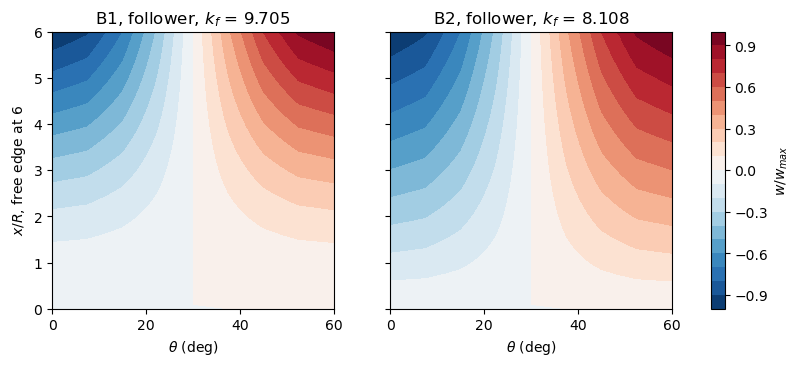

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, bc in zip(axes, ('B1', 'B2')):
    model = sr.CantileverModel(1, bc, 64, 8)
    kf, modes, _ = sr.linear_buckling(model, 'follower')
    w = modes[6::10, 0].reshape(65, 9)
    w = w/w.flat[np.argmax(np.abs(w))]
    cs = ax.contourf(model.y.reshape(65, 9)/sr.R*180/np.pi,
                     model.x.reshape(65, 9)/sr.R, w, 21, cmap='RdBu_r')
    ax.set_xlabel(r'$\theta$ (deg)')
    ax.set_title('%s, follower, $k_f$ = %.3f' % (bc, kf[0]))
axes[0].set_ylabel('$x/R$, free edge at 6')
fig.colorbar(cs, ax=axes, label='$w/w_{max}$')
plt.show()

## Riks analyses of the imperfect shell, Fig. 13

The imperfection is the $w$ part of the lowest mode of the follower
pressure, scaled to a largest $|w_0|$ of 1 % of $t$, outwards at the free
edge. The element takes no initial geometric imperfection; it is added
exactly as in the tutorial of the cylinder of Simo, Fox and Rifai: the
membrane strains of the imperfect shell are $\boldsymbol{\varepsilon}
(\boldsymbol{u} + \boldsymbol{u}_0) - \boldsymbol{\varepsilon}
(\boldsymbol{u}_0)$ and its curvatures $\boldsymbol{\kappa}
(\boldsymbol{u})$, which gives

$$
\boldsymbol{F}_{int,imp}(\boldsymbol{u}) =
\boldsymbol{F}_{int}(\boldsymbol{u} + \boldsymbol{u}_0) -
\boldsymbol{F}_{int}(\boldsymbol{u}_0) -
\boldsymbol{K}_G(\boldsymbol{N}_0) \boldsymbol{u}
$$

The derivation needs only non-linear membrane strains that are quadratic
forms of the rotations $\boldsymbol{G} \boldsymbol{u}$, and holds for the
Sanders-type kinematics with the rows $\boldsymbol{S}^w_{,x}$ and
$\boldsymbol{S}^w_{,y} - \boldsymbol{S}^v/R$ of $\boldsymbol{G}$; it is
verified in `tests/test_schweizerhof1984_cylinder.py` against the gradient
of a strain energy computed independently of the kernels. The pressure acts
on the imperfect surface, and the residual is

$$
\boldsymbol{R} = \boldsymbol{F}_{int,imp}(\boldsymbol{u}) - k
\boldsymbol{F}_p(\boldsymbol{u} + \boldsymbol{u}_0), \qquad
\boldsymbol{K}_T = \boldsymbol{K}_{C0} + \boldsymbol{K}_{CNL}(\boldsymbol{u}
+ \boldsymbol{u}_0) + \boldsymbol{K}_G(\boldsymbol{u}) -
\boldsymbol{K}_{GNL}(\boldsymbol{u}_0) + k \boldsymbol{K}_F
$$

with `calc_fext` the force vector $k \boldsymbol{F}_p(\boldsymbol{u}_0)$
and `calc_fint` the rest, the callables receiving the load factor `inc`
from structsolve (class `FollowerCylinder`). The tangent stiffness matrix
of the kernels, $\boldsymbol{K}_{C0} + \boldsymbol{K}_{CNL} +
\boldsymbol{K}_G$, is assembled by `CantileverModel.calc_KT`, vectorized
over the elements with NumPy, equal to that of `update_KCNL` to the
round-off and about 7 times faster than this kernel of the Sanders-type
element, which takes most of the run time otherwise.

The Riks method starts with an increment of 0.5 of $k$ and stops at the
first increment with a largest $|w|$ of $3t$, the end of the axis of Fig.
13. With `inertia=True` and `inertia_num_eigvals=6` structsolve factorizes
the tangent stiffness matrix of every converged increment with SuperLU and
records the sign of its determinant and, since the matrix is unsymmetric
and PARDISO's inertia does not apply, the number of negative real
eigenvalues among the 6 of smallest magnitude, by shift-invert with ARPACK
on the LU factorization. The current stiffness parameter of Bergan [2] is
computed as the stiffness $\Delta k/\|\Delta \boldsymbol{u}\|$ of each
increment, with the Euclidean norm of the increment of the unknown degrees
of freedom, over that of the first increment.

In [6]:
runs = {}
for bc, nx, ny in (('B1', 8, 3), ('B1', 16, 4), ('B1', 32, 8), ('B1', 64, 8),
                   ('B2', 64, 8)):
    r = sr.run_riks(1, bc, nx, ny, wmax=6.)
    runs[bc, nx, ny] = r
    an = r['an']
    fext = an.calc_fext()
    res = max(np.linalg.norm(an.calc_fint(c, inc=k) - k*fext)
              /np.linalg.norm(k*fext) for k, c in zip(an.increments, an.cs))
    ks, wt, neg, det = r['ks'], r['wt'], np.array(r['neg']), np.array(r['det'])
    imax = np.argmax(ks)
    print('%s %2d x %d: k_f (linear) %.4f, %3d increments, %5.1f s, max. '
          'residual %.0e; maximum k %.4f at w/t %.3f%s'
          % (bc, nx, ny, r['k_lin'], len(ks) - 1, r['elapsed'], res,
             ks[imax], wt[imax], ' (last increment)' if imax == len(ks) - 1
             else ''))
    print('    negative eigenvalues: %s; determinant signs: %s'
          % (dict(zip(*np.unique(neg, return_counts=True))),
             dict(zip(*np.unique(det, return_counts=True)))))
    first = np.flatnonzero(neg > 0)
    if first.size:
        i = first[0]
        print('    first negative eigenvalue at increment %d, k %.4f, w/t '
              '%.3f, after the maximum by %.1e in k' % (i + 1, ks[i + 1],
              wt[i + 1], ks[imax] - ks[i + 1]))

B1  8 x 3: k_f (linear) 10.9432,  33 increments,   1.3 s, max. residual 1e-09; maximum k 10.8551 at w/t 1.817
    negative eigenvalues: {np.int64(0): np.int64(20), np.int64(1): np.int64(13)}; determinant signs: {np.int64(-1): np.int64(13), np.int64(1): np.int64(20)}
    first negative eigenvalue at increment 21, k 10.8540, w/t 2.142, after the maximum by 1.1e-03 in k


B1 16 x 4: k_f (linear) 10.0889,  31 increments,   3.2 s, max. residual 2e-09; maximum k 10.0301 at w/t 2.672
    negative eigenvalues: {np.int64(0): np.int64(22), np.int64(1): np.int64(9)}; determinant signs: {np.int64(-1): np.int64(9), np.int64(1): np.int64(22)}
    first negative eigenvalue at increment 23, k 10.0296, w/t 3.032, after the maximum by 5.0e-04 in k


B1 32 x 8: k_f (linear) 9.7527,  30 increments,  14.2 s, max. residual 4e-09; maximum k 9.7154 at w/t 3.999
    negative eigenvalues: {np.int64(0): np.int64(25), np.int64(1): np.int64(5)}; determinant signs: {np.int64(-1): np.int64(5), np.int64(1): np.int64(25)}
    first negative eigenvalue at increment 26, k 9.7152, w/t 4.396, after the maximum by 2.0e-04 in k


B1 64 x 8: k_f (linear) 9.7048,  30 increments,  27.5 s, max. residual 3e-09; maximum k 9.6688 at w/t 4.037
    negative eigenvalues: {np.int64(0): np.int64(25), np.int64(1): np.int64(5)}; determinant signs: {np.int64(-1): np.int64(5), np.int64(1): np.int64(25)}
    first negative eigenvalue at increment 26, k 9.6687, w/t 4.438, after the maximum by 7.1e-05 in k


B2 64 x 8: k_f (linear) 8.1080,  32 increments, 111.2 s, max. residual 1e-09; maximum k 8.1155 at w/t 6.229 (last increment)
    negative eigenvalues: {np.int64(0): np.int64(32)}; determinant signs: {np.int64(1): np.int64(32)}


The residual of every converged increment, that of the whole follower
pressure on the imperfect shell, is below $10^{-8}$ of the load. The
iterations converge quadratically, with 3 to 5 corrections per increment,
because `calc_fext` declares the configuration `c` and returns the load
vector of the current configuration $\boldsymbol{F}_p(\boldsymbol{u} +
\boldsymbol{u}_0) = -\partial \boldsymbol{R}/\partial k$: with the constant
reference vector instead, the bordered system of the Riks method misses the
term $\partial \boldsymbol{F}_p/\partial \boldsymbol{u} \, \boldsymbol{u}$
of the derivative, the iterations converge linearly, by a factor of about
0.1 per correction, and the analyses take ten times longer.

Shell 1, B1: the load rises monotonically to a very flat maximum, $k =
9.669$ at $w/t = 4.04$ (64 x 8), 0.4 % below the linear $k_f$ of the same
mesh, and then decreases slowly; the maximum converges with the mesh like
$k_f$, 9.715 with 32 x 8 elements, 9.657 with 128 x 8 (run separately, 74
s). It is a limit point, not a bifurcation: the count of negative
eigenvalues of the tangent stiffness matrix is 0 up to the maximum and 1
from the first increment after it, together with the sign of the
determinant, and stays 1 up to $w/t = 6$ (8 in a separate run). Since the
count never exceeds 1, the sign of the determinant alone sees the same
critical point here. The coarse meshes have their maximum at smaller
deflections, 1.8 (8 x 3) and 2.7 (16 x 4), with the same pattern. With
B2 the load still rises at $w/t = 6$ (8.12 at 6.2, and 8.163 at $w/t = 8$
with 32 x 8 elements in a separate run), and the count stays 0: there is
no critical point on the computed path.

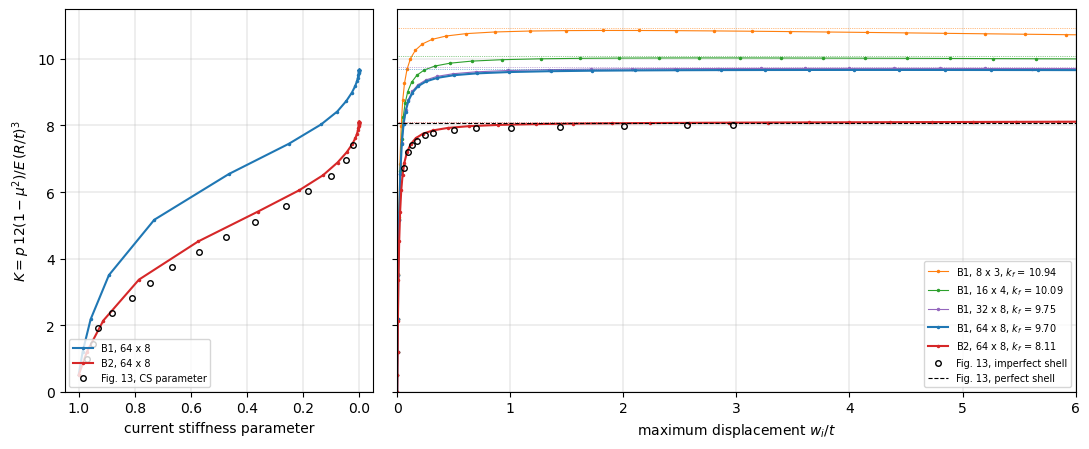

In [7]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True,
                               gridspec_kw=dict(width_ratios=(1, 2.2)))
colors = {('B1', 8, 3): 'C1', ('B1', 16, 4): 'C2', ('B1', 32, 8): 'C4',
          ('B1', 64, 8): 'C0', ('B2', 64, 8): 'C3'}
for key, r in runs.items():
    bc, nx, ny = key
    ax1.plot(r['wt'], r['ks'], '-', color=colors[key],
             marker='.', ms=3, lw=1.5 if nx == 64 else 0.8,
             label='%s, %d x %d, $k_f$ = %.2f' % (bc, nx, ny, r['k_lin']))
    ax1.axhline(r['k_lin'], color=colors[key], lw=0.5, ls=':')
    if nx == 64:
        ax0.plot(r['cs_param'], r['ks'][1:], '.-', ms=3, color=colors[key],
                 label='%s, %d x %d' % key)
d = np.array(sr.FIG13_IMPERFECT)
ax1.plot(d[:, 0], d[:, 1], 'o', mfc='none', color='k', ms=4,
         label='Fig. 13, imperfect shell')
ax1.axhline(sr.FIG13_PERFECT, color='k', lw=0.8, ls='--',
            label='Fig. 13, perfect shell')
d = np.array(sr.FIG13_CS)
ax0.plot(d[:, 0], d[:, 1], 'o', mfc='none', color='k', ms=4,
         label='Fig. 13, CS parameter')
ax0.set_xlim(1.05, -0.05)
ax0.set_xlabel('current stiffness parameter')
ax0.set_ylabel(r'$K = p \, 12 (1 - \mu^2)/E \, (R/t)^3$')
ax0.legend(fontsize=7, loc='lower left')
ax1.set_xlim(0, 6)
ax1.set_ylim(0, 11.5)
ax1.set_xlabel('maximum displacement $w_i/t$')
ax1.legend(fontsize=7, loc='lower right')
for ax in (ax0, ax1):
    ax.grid(lw=0.3)
fig.tight_layout()
plt.show()

Fig. 13 is read on the page rendered at 300 dpi, from the centre line of
the thick curve, with the axes calibrated on their ticks, to about $\pm
0.05$ in $K$ and $\pm 0.01$ in $w_i/t$; the horizontal line of the perfect
shell is at $K = 8.06$, and the curve of the imperfect shell reaches 8.01
at $w_i/t = 3$ without a maximum. The table compares the curve with the
paths of B1 and B2 (64 x 8) at the abscissae of the readings, and the
current stiffness parameter at the ordinates of the dashed curve (read to
$\pm 0.02$):

In [8]:
d = np.array(sr.FIG13_IMPERFECT)
print('%6s %8s %8s %8s' % ('w/t', 'Fig. 13', 'B1 64x8', 'B2 64x8'))
for wt, K in d:
    print('%6.3f %8.2f %8.3f %8.3f'
          % (wt, K, np.interp(wt, runs['B1', 64, 8]['wt'], runs['B1', 64, 8]['ks']),
             np.interp(wt, runs['B2', 64, 8]['wt'], runs['B2', 64, 8]['ks'])))
d = np.array(sr.FIG13_CS)
print()
print('%6s %10s %10s %10s' % ('K', 'CS Fig. 13', 'CS B1 64x8', 'CS B2 64x8'))
for cs, K in d:
    out = []
    for key in (('B1', 64, 8), ('B2', 64, 8)):
        r = runs[key]
        out.append(np.interp(K, r['ks'][1:], r['cs_param']))
    print('%6.2f %10.3f %10.3f %10.3f' % ((K, cs) + tuple(out)))

   w/t  Fig. 13  B1 64x8  B2 64x8
 0.058     6.72    8.089    6.773
 0.095     7.19    8.695    7.265
 0.133     7.41    8.983    7.497
 0.170     7.54    9.128    7.633
 0.245     7.71    9.305    7.774
 0.319     7.77    9.394    7.854
 0.506     7.85    9.512    7.943
 0.693     7.91    9.563    7.988
 1.002     7.93    9.606    8.025
 1.439     7.95    9.635    8.051
 2.007     7.99    9.653    8.068
 2.559     8.00    9.661    8.079
 2.970     8.01    9.665    8.085

     K CS Fig. 13 CS B1 64x8 CS B2 64x8
  0.98      0.970      0.990      0.980
  1.44      0.948      0.979      0.955
  1.90      0.930      0.965      0.927
  2.36      0.880      0.948      0.889
  2.82      0.810      0.926      0.842
  3.28      0.747      0.903      0.794
  3.74      0.667      0.869      0.716
  4.20      0.570      0.824      0.632
  4.66      0.475      0.779      0.539
  5.11      0.370      0.736      0.432
  5.57      0.260      0.652      0.324
  6.03      0.180      0.563      0.218
  6

The path of B1 does not match Fig. 13: its plateau, 9.67, is 21 % above
the 8.0 of the figure, as is its $k_f$, 9.70 in Table 4 and here. The path
of B2 matches it: within 0.10 (1.3 %) at every reading, the
plateau 8.09 at $w_i/t = 3$ against 8.01, with the knee at the same place,
$K = 6.77$ and 7.27 at $w_i/t = 0.058$ and 0.095 against 6.72 and 7.19,
and the current stiffness parameter within 0.07, 0.5 at $K = 4.55$ in the
figure and 4.85 here, a difference of the size of the error of the secant estimate of an
incremental quantity over the increments of the Riks method, which are
not those of the paper. The horizontal line of the perfect shell in the
figure, 8.06, is the $k_f$ of B2 of Table 4, 8.09 to 8.12, and of this
model, 8.11, within 0.6 %, and far from that of B1, 9.70. The text of the
paper, p. 1111, says that the nonlinear analysis is of shell 1 "with
boundary conditions B1"; the figure, its perfect-shell line and its
current stiffness parameter are those of B2, and the label of the text is
most likely wrong. The conclusion that the paper draws from the figure,
that the linear buckling load with the symmetrized load stiffness matrix
is an upper bound approached by the imperfect shell, holds for both
boundary conditions: with B1 the path tends to the limit point 0.4 %
below $k_f$, with B2 it rises slowly to $k_f$ and beyond it, the
post-buckling path of the perfect shell being stable at least up to $w/t
= 8$.

## References

[1] Schweizerhof, K., and Ramm, E., Displacement dependent pressure loads in
nonlinear finite element analyses, Computers & Structures, 18(6),
1099-1114, 1984, doi:10.1016/0045-7949(84)90154-8.

[2] Bergan, P. G., Automated incremental-iterative solution schemes, in
Numerical Methods for Nonlinear Problems, edited by C. Taylor, E. Hinton
and D. R. J. Owen, Pineridge Press, Swansea, 1980 (ref. [7] of [1]).